In [11]:
from pathlib import Path
import string

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

In [12]:
# --------------------------- FILES -----------------------------------------
DATA_DIR = Path("dat")                  # Directory containing the .dat files
OUTPUT_DIR = Path("figures_RS")       # Created automatically

PREFIX = "HH_V_RS_gM0.079e-3_gL0.180e-3_gT0.000e-3_I"
CURRENT_LABELS = [f"{i / 1000:.3f}" for i in range(150, 751, 50)]  # 13 currents
SKIP_ROWS = 0                        # Increase if .dat files have text headers

# ------------------------- PLOT SETTINGS -----------------------------------
TIME_WINDOW_MS = (450, 1600)
VOLTAGE_RANGE_MV = (-90, 60)
X_MAJOR_TICK_MS = 250
Y_MAJOR_TICK_MV = 40

TRACE_COLOR = "#1765AE"
TRACE_LINEWIDTH_PT = 0.90            # Thin strokes, good for dense spike trains

FONT_FAMILY = "DejaVu Sans"            # Portable; can set to "Arial" if installed
BASE_FONT_SIZE_PT = 9
PANEL_FONT_SIZE_PT = 9

# Approximately double-column panel figure sizes, with similar subplot widths.
FIGURE_SIZE_3X3_IN = (7.20, 5.35)
FIGURE_SIZE_2X2_IN = (4.90, 3.60)

SAVE_FORMATS = ("pdf", "svg", "png")    # Add "tiff" if required by the journal
RASTER_DPI = 600
SHOW_FIGURES = True
GENERATE_INDIVIDUALS = False

# ---------------------------- STYLE ----------------------------------------
plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.size": BASE_FONT_SIZE_PT,
    "axes.labelsize": BASE_FONT_SIZE_PT + 1,
    "xtick.labelsize": BASE_FONT_SIZE_PT - 1,
    "ytick.labelsize": BASE_FONT_SIZE_PT - 1,
    "axes.linewidth": 0.8,
    "lines.solid_capstyle": "round",
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
    "pdf.fonttype": 42,               # TrueType fonts; editable in vector editors
    "ps.fonttype": 42,
    "svg.fonttype": "none",           # Keep SVG text as actual editable text
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
})



In [13]:
def load_all_traces(data_dir: Path) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    paths = {label: data_dir / f"{PREFIX}{label}.dat" for label in CURRENT_LABELS}
    missing = [path.name for path in paths.values() if not path.is_file()]
    if missing:
        raise FileNotFoundError(
            f"Missing {len(missing)} of {len(paths)} required .dat files in "
            f"{data_dir.resolve()}:\n  " + "\n  ".join(missing)
            + "\n\nChange DATA_DIR above to the folder containing these files."
        )

    traces = {}
    for current, path in paths.items():
        try:
            data = np.loadtxt(
                path, usecols=(0, 1), comments="#", skiprows=SKIP_ROWS, ndmin=2
            )
        except ValueError as exc:
            raise ValueError(
                f"Cannot read numerical time/voltage columns from {path.name}. "
                "If there is a text header, adjust SKIP_ROWS."
            ) from exc

        if data.shape[0] == 0:
            raise ValueError(f"No rows of numeric data in {path.name}")
        if not np.isfinite(data).all():
            raise ValueError(f"Non-finite time/voltage value found in {path.name}")

        time_ms, voltage_mv = data[:, 0], data[:, 1]
        visible = ((time_ms >= TIME_WINDOW_MS[0]) &
                   (time_ms <= TIME_WINDOW_MS[1]))
        if not visible.any():
            raise ValueError(
                f"{path.name} contains no data in the chosen time window "
                f"{TIME_WINDOW_MS} ms."
            )
        traces[current] = (time_ms[visible], voltage_mv[visible])

    return traces


traces = load_all_traces(DATA_DIR)



In [14]:
def style_axis(ax):
    """Consistent, clean axes for publication-ready electrophysiology traces."""
    ax.set_xlim(*TIME_WINDOW_MS)
    ax.set_ylim(*VOLTAGE_RANGE_MV)
    ax.xaxis.set_major_locator(MultipleLocator(X_MAJOR_TICK_MS))
    ax.yaxis.set_major_locator(MultipleLocator(Y_MAJOR_TICK_MV))

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.tick_params(axis="both", which="major", labelsize=BASE_FONT_SIZE_PT - 1,
                   width=0.8, length=3, pad=3)
    ax.grid(False)


def save_figure(fig, filename_stem: str):
    """Export the same figure in vector and raster formats."""
    for extension in SAVE_FORMATS:
        output = OUTPUT_DIR / f"{filename_stem}.{extension}"
        #fig.savefig(output, dpi=RASTER_DPI, bbox_inches="tight",pad_inches=0.04, facecolor="white")
        print(f"Saved {output}")


def plot_multipanel(currents, nrows, ncols, figure_size, filename_stem,
                    letter_offset=0):
    """Plot a set of RS traces without modifying their original samples."""
    if len(currents) != nrows * ncols:
        raise ValueError("currents must exactly fill the requested subplot grid")

    fig, axes = plt.subplots(nrows, ncols, figsize=figure_size,
                             sharex=True, sharey=True, squeeze=False)

    # Space for the top-of-panel annotations and one shared x/y label.
    fig.subplots_adjust(left=0.102, right=0.990, bottom=0.125,
                        top=0.925, wspace=0.18, hspace=0.38)

    for j, (current, ax) in enumerate(zip(currents, axes.flat)):
        t, v = traces[current]
        ax.plot(t, v, color=TRACE_COLOR, lw=TRACE_LINEWIDTH_PT,
                rasterized=False)
        style_axis(ax)

        # Letters and amplitudes OUTSIDE the plotting region avoid spike overlap.
        letter = string.ascii_lowercase[letter_offset + j]
        ax.text(0.0, 1.04, letter, transform=ax.transAxes,
                ha="left", va="bottom", fontweight="bold",
                fontsize=PANEL_FONT_SIZE_PT, clip_on=False)
        ax.text(1.0, 1.04, f"I = {current} nA", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=PANEL_FONT_SIZE_PT,
                clip_on=False)
        ax.label_outer()   # Hide inner-panel tick labels.

    fig.supxlabel("Time (ms)", fontsize=BASE_FONT_SIZE_PT + 1, y=0.030)
    fig.supylabel("Membrane potential (mV)",
                 fontsize=BASE_FONT_SIZE_PT + 1, x=0.013)

    save_figure(fig, filename_stem)
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)
    return filename_stem


Saved figures_RS/Analise_1_RS_Painel_01_I0150_a_0550.pdf
Saved figures_RS/Analise_1_RS_Painel_01_I0150_a_0550.svg
Saved figures_RS/Analise_1_RS_Painel_01_I0150_a_0550.png


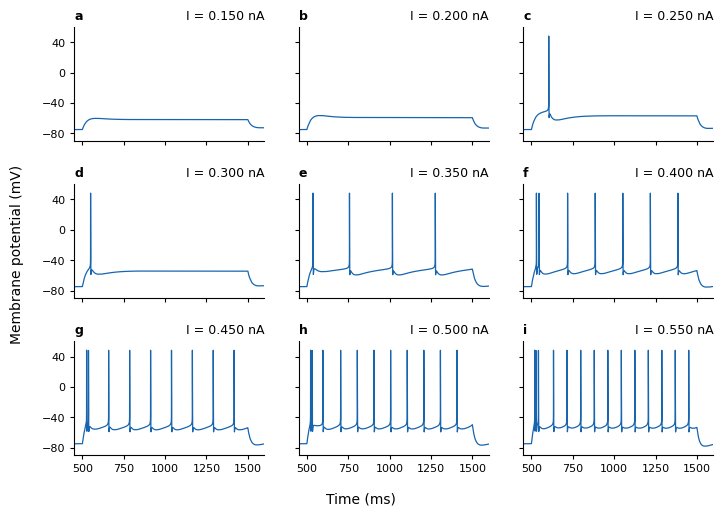

'Analise_1_RS_Painel_01_I0150_a_0550'

In [15]:
# Figure 1 — the first nine currents (0.150–0.550 nA), panels a–i.
plot_multipanel(
    currents=CURRENT_LABELS[:9],
    nrows=3,
    ncols=3,
    figure_size=FIGURE_SIZE_3X3_IN,
    filename_stem="Analise_1_RS_Painel_01_I0150_a_0550",
    letter_offset=0,
)
